# ¿Qué explica la variación mensual del ingreso?
Datos sintéticos de Northwind (2/1/2026 al 29/8/2026). Warehouse generado por `src/pipeline.py`.

**Identidad:** ingreso = pedidos × líneas por pedido × unidades por línea × precio por unidad.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

con = sqlite3.connect("../data/warehouse.db")

## 1. Tabla mensual y las 4 palancas

In [2]:
mensual = pd.read_sql("""
    SELECT f.anio_mes AS mes, COUNT(DISTINCT v.pedido_id) AS pedidos, COUNT(*) AS lineas,
           SUM(v.cantidad) AS unidades, SUM(v.monto_linea) AS ingreso
    FROM fact_ventas_lineas v JOIN dim_fecha f ON v.fecha_key = f.fecha_key
    GROUP BY f.anio_mes ORDER BY f.anio_mes""", con)
mensual["lineas_x_pedido"] = mensual["lineas"] / mensual["pedidos"]
mensual["unidades_x_linea"] = mensual["unidades"] / mensual["lineas"]
mensual["precio_x_unidad"] = mensual["ingreso"] / mensual["unidades"]
palancas = ["pedidos", "lineas_x_pedido", "unidades_x_linea", "precio_x_unidad"]
print("identidad:", np.allclose(mensual[palancas].prod(axis=1), mensual["ingreso"]))
mensual.round(2)

identidad: True


,mes,pedidos,lineas,unidades,ingreso,lineas_x_pedido,unidades_x_linea,precio_x_unidad
0,2026-01,12,34,382,4941387.71,2.83,11.24,12935.57
1,2026-02,13,35,344,4158203.56,2.69,9.83,12087.80
2,2026-03,21,62,700,8816187.96,2.95,11.29,12594.55
3,2026-04,15,46,464,5395962.57,3.07,10.09,11629.23
4,2026-05,10,26,249,2846036.74,2.60,9.58,11429.87
5,2026-06,20,59,670,10355550.62,2.95,11.36,15456.05
6,2026-07,15,50,579,7240139.59,3.33,11.58,12504.56
7,2026-08,14,49,551,7530380.32,3.50,11.24,13666.75


## 2. ¿Cuánto explica cada palanca? (descomposición en logaritmos)
Como el ingreso es un producto, sus logaritmos suman. La parte de cada palanca es `cov(ln palanca, ln ingreso) / var(ln ingreso)`. Es contabilidad, no causalidad.

In [3]:
logs = np.log(mensual[palancas + ["ingreso"]])
aporte = pd.Series({p: logs[p].cov(logs["ingreso"]) / logs["ingreso"].var() for p in palancas})
print((aporte * 100).round(1).to_dict(), "suma:", round(aporte.sum(), 6))

{'pedidos': 52.5, 'lineas_x_pedido': 15.3, 'unidades_x_linea': 15.0, 'precio_x_unidad': 17.3} suma: 1.0


## 3. Junio contra el promedio de los 8 meses

In [4]:
desvio = logs - logs.mean()
desvio.insert(0, "mes", mensual["mes"])
junio = desvio[desvio["mes"] == "2026-06"].iloc[0]
print(junio[palancas + ["ingreso"]].round(3).to_dict())
print("peso en junio:", {p: round(junio[p] / junio["ingreso"] * 100, 1) for p in palancas})

{'pedidos': 0.315, 'lineas_x_pedido': -0.009, 'unidades_x_linea': 0.055, 'precio_x_unidad': 0.194, 'ingreso': 0.554}
peso en junio: {'pedidos': np.float64(56.8), 'lineas_x_pedido': np.float64(-1.7), 'unidades_x_linea': np.float64(9.9), 'precio_x_unidad': np.float64(35.0)}


## 4. ¿Los pedidos mensuales varían más que el azar?

In [5]:
x = mensual["pedidos"].values
mu = x.mean()
chi2 = ((x - mu) ** 2 / mu).sum()
p_disp = 1 - stats.chi2.cdf(chi2, df=len(x) - 1)
print("media", mu, "varianza", round(x.var(ddof=1), 3), "chi2", round(chi2, 3), "p", round(p_disp, 4))

media 15.0 varianza 14.286 chi2 6.667 p 0.4644


## 5. Ticket de junio contra el resto (Welch)
Ojo: junio se eligió *después* de ver que era el más alto (análisis post hoc).

In [6]:
ped = pd.read_sql("""
    SELECT v.pedido_id, f.anio_mes AS mes, SUM(v.monto_linea) AS monto
    FROM fact_ventas_lineas v JOIN dim_fecha f ON v.fecha_key = f.fecha_key
    GROUP BY v.pedido_id""", con)
jun = ped.loc[ped.mes == "2026-06", "monto"]
resto = ped.loc[ped.mes != "2026-06", "monto"]
t = stats.ttest_ind(jun, resto, equal_var=False)
dif = jun.mean() - resto.mean()
ic = t.confidence_interval(0.95)
sp = np.sqrt(((len(jun)-1)*jun.var(ddof=1) + (len(resto)-1)*resto.var(ddof=1)) / (len(jun)+len(resto)-2))
print("n", len(jun), len(resto), "| medias", round(jun.mean(), 2), round(resto.mean(), 2), "| dif", round(dif, 2))
print("t", round(t.statistic, 3), "p", round(t.pvalue, 4), "IC95", round(ic.low, 2), round(ic.high, 2), "d", round(dif / sp, 3))
print("medianas", round(jun.median(), 2), round(resto.median(), 2))

n 20 100 | medias 517777.53 409282.98 | dif 108494.55
t 1.421 p 0.1674 IC95 -48597.7 265586.8 d 0.376
medianas 490322.8 388735.23


## 6. Mezcla de productos caros (precio de lista ≥ ₡20,000)

In [7]:
mix = pd.read_sql("""
    SELECT f.anio_mes AS mes,
           ROUND(100.0 * SUM(CASE WHEN p.precio_lista >= 20000 THEN v.cantidad ELSE 0 END) / SUM(v.cantidad), 1) AS pct_unidades_caras
    FROM fact_ventas_lineas v
    JOIN dim_fecha f ON v.fecha_key = f.fecha_key
    JOIN dim_producto p ON v.producto_key = p.producto_key
    GROUP BY f.anio_mes ORDER BY f.anio_mes""", con)
print(mix.to_string(index=False))

    mes  pct_unidades_caras
2026-01                25.9
2026-02                21.8
2026-03                19.4
2026-04                19.6
2026-05                19.3
2026-06                33.1
2026-07                20.4
2026-08                37.2


## 7. Gráficos

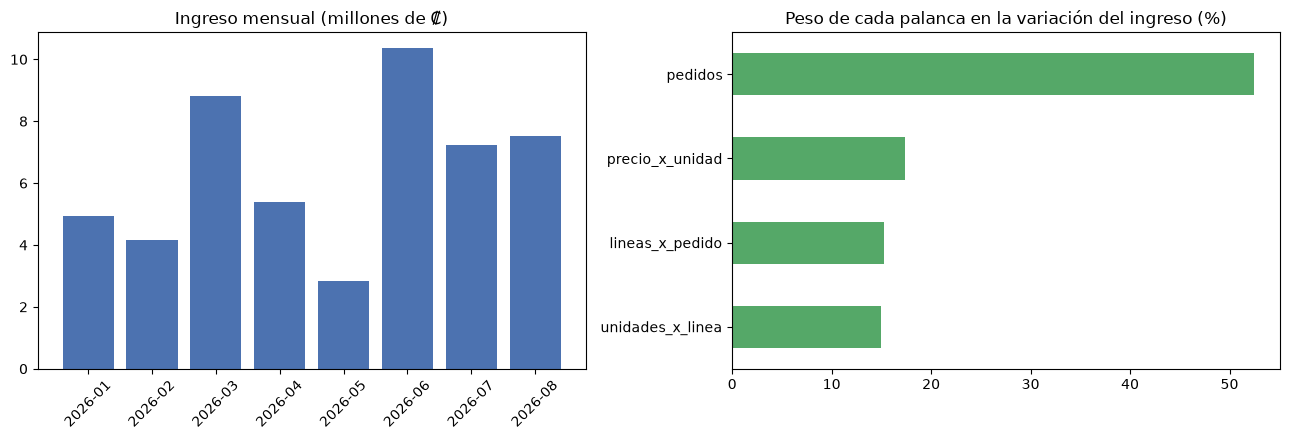

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(mensual["mes"], mensual["ingreso"] / 1e6, color="#4C72B0")
ax[0].set_title("Ingreso mensual (millones de ₡)")
ax[0].tick_params(axis="x", rotation=45)
(aporte * 100).sort_values().plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title("Peso de cada palanca en la variación del ingreso (%)")
plt.tight_layout()
plt.show()

## 8. Mis respuestas de interpretación
_Escribí acá, con tus palabras (2 a 3 líneas cada una):_

1. ¿Dónde mirar primero según la descomposición?
2. ¿Se contradicen el 52.5% de los pedidos y el p = 0.46 de la prueba de azar?
3. Ticket de junio: ¿qué puedo afirmar y qué no? ¿Qué problema tiene haber elegido junio después de verlo?
4. Junio y agosto tienen más unidades caras: ¿prueba que la mezcla causa el ticket más alto? ¿Qué falta?
5. Si el ticket promedio global subiera, ¿qué segmentaría antes de interpretar?